# Tutorial 04 — Asteroid thermal model on a real ephemeris: (101955) Bennu

This notebook runs PTM3D's **generic-body** thermal path with a real SPICE
ephemeris and a real facet shape model, instead of the analytic Keplerian
orbit and synthetic icosphere in [tutorial 03](03_asteroid_thermal.ipynb).
Body: **(101955) Bennu**, the OSIRIS-REx sample-return target.

**Companion files:** [`examples/quickstart_asteroid_bennu.yaml`](../../../examples/quickstart_asteroid_bennu.yaml),
plus the body's kernel/shape data under
[`data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/`](../../../data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/)
and [`data/kernels/bennu.tm`](../../../data/kernels/bennu.tm).

**Cost:** three CPU-only runs of roughly 10 s each on a many-core workstation
(2692-facet mesh, 2 rotations of output after a ~40-rotation equilibration);
under two minutes for the whole notebook including plotting, and a few
minutes on a laptop. Needs the `ptm` package: `pip install -e .` from the
repository root.

**Related tutorials:** [03 — asteroid on a Keplerian orbit](03_asteroid_thermal.ipynb)
(this notebook's counterpart), [06 — interpreting the outputs](../06_interpreting_outputs.md).

## When to use a SPICE ephemeris instead of Keplerian elements

Tutorial 03's two-body Keplerian propagation is exact for an isolated
Sun-asteroid pair with fixed osculating elements. A SPICE ephemeris (a `.bsp`
SPK file) instead carries a **fitted or integrated trajectory** — the result
of an orbit determination that has already absorbed planetary perturbations,
or, for a spacecraft-target body, radiometric tracking. Use SPICE when a
result needs to match:

- **real epochs** (a specific calendar date, not "hour 0 of an idealized orbit"),
- **accurate distance and phase angle** at that epoch, including secular drift
  away from a fixed osculating-element approximation (Section 6 measures this
  directly for Bennu), and
- **real mission geometry** — flyby/proximity-operations windows, light-time,
  and the same trajectory files a navigation team used.

## Learning goals

1. Configure and run PTM3D's generic-body **SPICE** ephemeris path, and state
   exactly what external data it needs beyond tutorial 03's Keplerian config.
2. Source a real small-body shape model: check DAMIT, and when a target is
   not there, use the appropriate public alternative (here, the PDS Small
   Bodies Node archive of the Nolan et al. 2013 radar shape model).
3. Read the SPICE-specific config blocks against tutorial 03's Keplerian ones,
   side by side.
4. Produce a shape-resolved temperature render, an equatorial diurnal curve
   annotated with the real heliocentric distance, and a perihelion/aphelion
   comparison using Bennu's real orbit.
5. Quantify, on this engine, how much a fixed Keplerian approximation drifts
   from the real ephemeris at a given epoch — the concrete answer to "why
   mission work needs ephemerides."

## 1. Environment check

A SPICE-driven generic body needs three tiers of data, all under `data/`:

1. **Shared generic kernels** (leapseconds, planetary constants, planetary
   ephemeris) — the same ones tutorial 01/02 use, fetched by
   `scripts/fetch_kernels.py --bodies moon` into `data/kernels/`.
2. **A per-body meta-kernel** (`data/kernels/bennu.tm`) that tells SPICE which
   kernels to load for this body specifically.
3. **Bennu's own ephemeris and shape**, under
   `data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/` — not auto-fetched
   by any script in this repo; sourced and documented below.

`scripts/fetch_kernels.py` only knows three named bodies (`moon`, `europa`,
`mercury`) — it has no small-body mode. `src/python/data_manager.py`'s
`fetch_and_cache_body()` is the library call the `generic_body` path uses to
populate `data/horizons_cache/bodies/<name>/` for a body reachable through
JPL Horizons; the cells below call the same building blocks it uses
(`src/python/horizons/horizons_client.py`, `src/python/damit/`) directly, so
the notebook shows every step rather than one opaque function call.

In [1]:
import hashlib
import os
import re
import subprocess
import sys
import time
from pathlib import Path

try:
    import ptm
except ImportError:
    raise SystemExit(
        "The `ptm` package is not importable. Install it from the repository "
        f"root -- it brings numpy, matplotlib and PyYAML with it:\n"
        f"    {sys.executable} -m pip install -e .")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import yaml
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from ptm import Results, paths, plots
from ptm import run as engine

print("Python     :", sys.version.split()[0])
print("ptm        :", ptm.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

REPO_ROOT = paths.find_repo_root(Path.cwd())
if REPO_ROOT is None:
    raise SystemExit("Open this notebook from inside a PTM3D checkout, or set "
                     "$PTM_ROOT.")
BODY_DIR = REPO_ROOT / "data" / "horizons_cache" / "bodies" / "101955_Bennu_(1999_RQ36)"
print("Repo root  :", REPO_ROOT)
print("Body dir   :", BODY_DIR)

Python     : 3.8.18
ptm        : 0.2.0
numpy      : 1.24.4
matplotlib : 3.7.5
Repo root  : /Users/paha3326/Projects/ptm-ux5a
Body dir   : /Users/paha3326/Projects/ptm-ux5a/data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)


In [2]:
BIN = paths.find_engine_executable("ptm_thermal_sim", search_roots=[REPO_ROOT])
if BIN is None:
    raise SystemExit(
        f"ptm_thermal_sim not found in {REPO_ROOT}/build/bin (nor in "
        "$PTM_BUILD_DIR). Build the CPU-only core first -- INSTALL.md "
        "'TL;DR (Linux/macOS, CPU-only)':\n"
        "  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\\n"
        "        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=/path/to/cspice\n"
        "  cmake --build build --target ptm_thermal_sim -j")

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=str(REPO_ROOT),
                        capture_output=True, text=True).stdout.strip()
help_run = subprocess.run([str(BIN), "--help"], capture_output=True, text=True)

print("Binary     :", BIN)
print("  md5      :", hashlib.md5(BIN.read_bytes()).hexdigest())
print("  commit   :", commit or "(git rev-parse failed -- not fatal)")
print("  --help rc:", help_run.returncode, "(0 = OK)")
assert help_run.returncode == 0, "ptm_thermal_sim --help did not exit 0 -- broken build"
print("\nThis tutorial runs the CPU core throughout (thermal.use_gpu: false):")
print("the mesh is small enough that the CPU path is the faster one, and it")
print("keeps the tutorial runnable on machines with no OpenCL device.")

Binary     : /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim
  md5      : 96b7dca84d25df4d31d21e246632fe58
  commit   : 83d45f6
  --help rc: 0 (0 = OK)

This tutorial runs the CPU core throughout (thermal.use_gpu: false):
the mesh is small enough that the CPU path is the faster one, and it
keeps the tutorial runnable on machines with no OpenCL device.


In [3]:
import urllib.request

# Tier 1: shared generic kernels, fetched the same way tutorials 01/02 do.
LSK = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"
DE440S = REPO_ROOT / "data" / "kernels" / "spk" / "de440s.bsp"
if not (LSK.exists() and DE440S.exists()):
    print("Fetching shared generic kernels (--bodies moon; also covers Mercury)...")
    subprocess.run([sys.executable, str(REPO_ROOT / "scripts" / "fetch_kernels.py"),
                     "--bodies", "moon"], cwd=REPO_ROOT, check=True)
else:
    print("Shared generic kernels already present:")
for p in (REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls",
          REPO_ROOT / "data" / "kernels" / "pck" / "pck00011.tpc",
          REPO_ROOT / "data" / "kernels" / "spk" / "de440s.bsp"):
    print(f"  {p.relative_to(REPO_ROOT)}  ({p.stat().st_size/1024:.1f} KB)")

# Tier 2 + 3: the per-body meta-kernel and Bennu's own ephemeris + shape.
BENNU_TM = REPO_ROOT / "data" / "kernels" / "bennu.tm"
SPK = BODY_DIR / "ephemeris.spk"
SHAPE = BODY_DIR / "bennu_radar_shape.obj"
for label, p in [("meta-kernel", BENNU_TM), ("ephemeris SPK", SPK), ("shape OBJ", SHAPE)]:
    assert p.exists(), f"missing {label}: {p}"
    print(f"{label:14s}: {p.relative_to(REPO_ROOT)}  ({p.stat().st_size/1024:.1f} KB)")

print(f"\nTotal Bennu-specific data: {(SPK.stat().st_size + SHAPE.stat().st_size)/1024:.0f} KB,"
      " already tracked in this checkout. The next three cells document where each file"
      " came from and how to regenerate them for a different body.")

Shared generic kernels already present:
  data/kernels/lsk/naif0012.tls  (5.1 KB)
  data/kernels/pck/pck00011.tpc  (128.2 KB)
  data/kernels/spk/de440s.bsp  (31959.0 KB)
meta-kernel   : data/kernels/bennu.tm  (2.3 KB)
ephemeris SPK : data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/ephemeris.spk  (25.0 KB)
shape OBJ     : data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/bennu_radar_shape.obj  (87.1 KB)

Total Bennu-specific data: 112 KB, already tracked in this checkout. The next three cells document where each file came from and how to regenerate them for a different body.


### Shape model: DAMIT first, PDS SBN as the fallback

`src/python/damit/damit_client.py` searches [DAMIT](https://damit.cuni.cz/)
(the Database of Asteroid Models from Inversion Techniques) by name or
number. Bennu's primary shape models are not lightcurve-inversion products —
they come from radar delay-Doppler imaging (Nolan et al. 2013) and,
post-encounter, OSIRIS-REx laser altimetry — so this is a real, not
rhetorical, check.

In [4]:
# `damit` and `horizons` are packages under src/python/ that the `ptm`
# distribution does not (yet) carry, so this one import still needs the path.
sys.path.insert(0, str(REPO_ROOT / "src" / "python"))
from damit import DAMITClient

damit = DAMITClient()
for query in ("Bennu", "101955"):
    results = damit.search_asteroid(query)
    print(f"DAMIT search('{query}') -> {len(results)} match(es)")
print("\nDAMIT does not carry a Bennu shape model. Falling back to the PDS Small Bodies")
print("Node archive of the radar shape model instead (next cell).")

DAMIT search('Bennu') -> 0 match(es)


DAMIT search('101955') -> 0 match(es)

DAMIT does not carry a Bennu shape model. Falling back to the PDS Small Bodies
Node archive of the radar shape model instead (next cell).


### Shape source actually used: PDS SBN radar shape model

[PDS SBN — Shape Model of Asteroid (101955) Bennu](https://sbn.psi.edu/pds/resource/bennushape.html),
`urn:nasa:pds:ast-bennu.radar.shape-model::1.1`
([bundle download](https://sbnarchive.psi.edu/pds4/non_mission/ast-bennu.radar.shape-model_V1_1.zip),
1.2 MB) — Nolan, M.C. et al. (2013), *Shape model and surface properties of
the OSIRIS-REx target asteroid (101955) Bennu from radar and lightcurve
observations*, Icarus 226, 629–640,
[doi:10.1016/j.icarus.2013.05.028](https://doi.org/10.1016/j.icarus.2013.05.028).
NASA PDS archival data (public domain; cite the paper on reuse).

The archive's `data/101955bennu.tab` uses the exact `v x y z` / `f i j k`
format DAMIT shape files use — `src/python/damit/shape_converter.py` reads
either one unmodified. 1348 vertices, 2692 facets, already in kilometers
(mean vertex radius 244.7 m, matching the diameter SBDB reports for Bennu to
about 1%) — small enough to convert and commit as-is, no decimation needed.
The pole (`pole.tab`, ecliptic λ=45°, β=−88°) and rotation period
(`rotate.tab`, 4.29746 h, Hergenrother et al. 2013) ship in the same bundle
and are what `generic_body.spin` below uses, converted from ecliptic to
equatorial with the same formula `damit_client.DAMITSpinParams` uses for a
real DAMIT model.

The converted file
[`bennu_radar_shape.obj`](../../../data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/bennu_radar_shape.obj)
(88 KB) carries this citation in its own header.

In [5]:
n_v = sum(1 for l in SHAPE.read_text().splitlines() if l.startswith("v "))
n_f = sum(1 for l in SHAPE.read_text().splitlines() if l.startswith("f "))
print(f"{SHAPE.name}: {n_v} vertices, {n_f} facets, {SHAPE.stat().st_size/1024:.0f} KB")
print("\nHeader (citation + provenance):")
print("\n".join(l for l in SHAPE.read_text().splitlines() if l.startswith("#")))

bennu_radar_shape.obj: 1348 vertices, 2692 facets, 87 KB

Header (citation + provenance):
# Wavefront OBJ shape model -- asteroid (101955) Bennu
#
# Source: Nolan, M.C., Magri, C., Howell, E.S., Benner, L.A.M., Giorgini, J.D.,
#   Hergenrother, C.W., Hudson, R.S., Lauretta, D.S., Margot, J.L., Ostro, S.J.,
#   Scheeres, D.J. (2013). Shape model and surface properties of the OSIRIS-REx
#   target asteroid (101955) Bennu from radar and lightcurve observations.
#   Icarus 226, 629-640. doi:10.1016/j.icarus.2013.05.028
# Archive: PDS Small Bodies Node, urn:nasa:pds:ast-bennu.radar.shape-model::1.1
#   https://sbnarchive.psi.edu/pds4/non_mission/ast-bennu.radar.shape-model_V1_1.zip
#   NASA PDS archival data; public domain / freely redistributable with citation.
# Converted from the archive's native "v x y z / f i j k" vertex-facet table
# (data/101955bennu.tab) verbatim -- vertices already in km, center of mass
# origin, principal-axis frame, z = spin (long) axis. 1348 vertices, 2692
# fac

### Ephemeris source: an archived mission SPK, not an on-demand one

JPL Horizons can generate a small-body SPK on request
(`src/python/horizons/horizons_client.py: HorizonsClient.download_spk`, used
by the `269_Justitia`/`623_Chimaera`/`13294_Rockox` bodies already in
`data/horizons_cache/`) — but not for Bennu:

```
COMMAND='101955', EPHEM_TYPE=SPK, CENTER='500@0' ->
"SPK creation is not available for pre-computed objects in the major body index"
```

Horizons declines ad hoc SPK generation for a handful of small bodies with
spacecraft-quality tracking, Bennu among them. The correct substitute is the
mission's own archived SPK: **`bennu_refdrmc_v1.bsp`**, OSIRIS-REx SPICE
archive, NAIF PDS4 node,
[spice_kernels/spk/bennu_refdrmc_v1.bsp](https://naif.jpl.nasa.gov/pub/naif/pds/pds4/orex/orex_spice/spice_kernels/spk/bennu_refdrmc_v1.bsp)
(25.6 KB) — "ephemerides of asteroid (101955) Bennu, created by the
OSIRIS-REx science team," covering 2014-12-31 through 2023-05-30. This is a
better source for this body than an on-demand file would have been anyway:
it is the trajectory solution the mission itself flew against.

`data_manager.read_spk_body_id()` reads the body id an SPK actually declares
rather than computing one from the asteroid number — Horizons migrated
small-body ids between a `2000000+N` and a `20000000+N` scheme, and a
computed id can be wrong (see `269_Justitia`'s cached config, which corrects
exactly this). This SPK declares Bennu as **2101955**.

In [6]:
import spiceypy as sp

sp.furnsh(str(LSK))
sp.furnsh(str(SPK))
cov = sp.spkcov(str(SPK), 2101955)
print("SPK target id : 2101955 (read directly, not computed from 101955)")
print(f"SPK coverage  : {sp.et2utc(cov[0], 'C', 0)}  to  {sp.et2utc(cov[1], 'C', 0)}")
sp.kclear()

SPK target id : 2101955 (read directly, not computed from 101955)
SPK coverage  : 2014 DEC 31 23:58:53  to  2023 MAY 30 23:58:51


### The meta-kernel: how the path resolves

`generic_body.spice_metakernel` is resolved as
`<compiled-in kernel directory>/<value>` by plain string concatenation
(`illumination_model.cpp`, `initialize_spice()`) — not as a path relative to
the config file or the working directory. A bare filename living directly in
`data/kernels/` (like `moon.tm`/`europa.tm`/`mercury.tm` already do) is the
form that resolves correctly; that is why `data/kernels/bennu.tm` sits there
rather than next to Bennu's other files. Its own `PATH_VALUES` then points
back at `data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/` for
`ephemeris.spk`, relative to the repository root as usual.

In [7]:
print((REPO_ROOT / "data" / "kernels" / "bennu.tm").read_text())

KPL/MK

   PTM3D meta-kernel: asteroid (101955) Bennu, generic-body SPICE path.
   Used by docs/tutorials/notebooks/04_asteroid_spice.ipynb and
   examples/quickstart_asteroid_bennu.yaml.

   Paths are RELATIVE to the repository root -- run ptm_thermal_sim from the
   repo root (or edit PATH_VALUES to an absolute path).

   This file lives in data/kernels/ (a bare filename, like moon.tm/europa.tm/
   mercury.tm) because generic_body.spice_metakernel is resolved as
   "<compiled-in SPICE_KERNELS_DIR>/<spice_metakernel value>" (plain string
   concatenation, illumination_model.cpp initialize_spice()) -- an absolute or
   data/horizons_cache-relative value there does not resolve. The body-specific
   ephemeris.spk it loads below is NOT here; it stays with the body under
   data/horizons_cache/bodies/, resolved via the BODY path symbol instead.

   Shared kernels (leapseconds, planetary constants, planetary ephemeris) come
   from data/kernels/, populated by:  python3 scripts/fetch_kernels

## 2. Config walkthrough

The full config, as shipped:

In [8]:
cfg_path = REPO_ROOT / "examples" / "quickstart_asteroid_bennu.yaml"
print(cfg_path.read_text())

# PTM3D quickstart: asteroid (101955) Bennu on its real SPICE ephemeris, with
# its real DAMIT-class radar shape model, near the 2019-01-10 perihelion of
# its orbit during the OSIRIS-REx proximity-operations era.
#
# Notebook counterpart of examples/quickstart_asteroid_diurnal.yaml (tutorial
# 03, Keplerian orbit, fictional body). This config is that notebook's SPICE
# counterpart: same generic-body thermal path, but the Sun-body vector comes
# from a real ephemeris file instead of an analytic two-body propagation, and
# the shape is Bennu's actual radar-derived facet model instead of a sphere.
# See docs/tutorials/notebooks/04_asteroid_spice.ipynb for the full walkthrough.
#
# CPU-only, laptop-friendly (2692-facet mesh, well under a minute measured on
# an 8-thread run -- see the notebook's Provenance cell for the exact number).
#
# Run FROM THE REPOSITORY ROOT:
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_bennu.yaml
#
# ------------------------------------

### SPICE blocks vs. tutorial 03's Keplerian blocks, side by side

| | Tutorial 03 (Keplerian) | Tutorial 04 (SPICE, this notebook) |
|---|---|---|
| `generic_body.ephemeris_source` | `keplerian` | `spice` |
| Sun-body vector | analytic two-body propagation of `orbit:` | `spkpos_c("SUN", ..., "LT+S", ...)` against `ephemeris.spk` (light-time + stellar-aberration corrected) |
| `spice_metakernel` / `naif_id` | not present | required — see the meta-kernel note above |
| `orbit:` block | the position source | present but a **fallback only**, used if a requested epoch falls outside `ephemeris.spk`'s coverage |
| `shape.type` | `spherical`, radius only | `custom_mesh`, a real facet model |
| `spin.pole_ra_deg`/`pole_dec_deg` | arbitrary teaching values (zero obliquity) | Bennu's real pole, ecliptic-to-equatorial converted (~178° obliquity — a slow retrograde rotator) |
| External data | none | shared kernels + one body-specific SPK + one shape file |

### Thermophysical properties

As in tutorial 03, only `generic_body.surface:` is read for a generic body's
thermophysical properties — the top-level `thermophysical:` block is inert
except `use_default_albedo` (see `docs/KNOWN_LIMITATIONS.md`'s section on
generic-body config routing). The values here are Bennu's, not arbitrary:

- **Albedo** 0.017 bolometric Bond albedo (Golish et al. 2021, OCAMS phase
  curve); Bennu's *geometric* albedo is 0.044 (JPL SBDB) — a very dark,
  B-type/CI-CM-analog surface.
- **Thermal inertia** $TI=\sqrt{k\rho c_p}=\sqrt{0.075\times1500\times800}=300.0$
  SI, matching the OTES-derived global value in Rozitis et al. (2020,
  *Science Advances* 6, eaay4835) — locally 200–700 SI over
  boulders/fines. `rhos`/`cp0` reuse tutorial 03's regolith values for
  continuity, not a measurement: Bennu's real *bulk* density is
  ~1190 kg/m³ (DellaGiustina et al. 2019) — a whole-body rubble-pile
  macroporosity number, not this model's surface-layer grain density.
- **Spin** period 4.29746 h; pole at ecliptic (λ=45°, β=−88°) → equatorial
  (RA=86.64°, Dec=−65.11°) via the standard J2000-obliquity rotation —
  an obliquity of ~178°, i.e. retrograde.

## 3. Run it — at Bennu's 2019-01-10 perihelion

`ephemeris.spk` covers 2014-12-31 to 2023-05-30. Scanning that window (one
sample per day, `spkpos` against the Sun) finds the perihelion nearest the
middle of OSIRIS-REx proximity operations: **2019-01-10, r=0.897 AU**
— not assumed from a catalog, found directly from the file this run also
loads. Section 5.4 revisits this scan to find the matching aphelion.

In [9]:
def run_ptm(config_rel_path, label):
    """Run ptm_thermal_sim to completion; return (stdout text, wall seconds).

    ptm.run.EngineProcess is the same process driver the GUI uses: it reads
    both streams, classifies each line by content rather than by which stream
    it arrived on (the engine writes informational banners to stderr), and
    watches the child's CPU clock for a stall.
    """
    cmd = engine.build_command(BIN, REPO_ROOT / config_rel_path)
    out, t0 = [], time.time()
    rc = engine.EngineProcess(cmd, working_dir=REPO_ROOT, on_output=out.append,
                              on_warning=out.append, on_error=out.append).run()
    wall = time.time() - t0
    print(f"[{label}] rc={rc}  wall={wall:.1f} s")
    if rc != 0:
        raise RuntimeError(f"{label} failed, rc={rc}:\n" + "\n".join(out[-40:]))
    return "\n".join(out), wall


stdout_perih, wall_perih = run_ptm("examples/quickstart_asteroid_bennu.yaml",
                                   "perihelion 2019-01-10")

[perihelion 2019-01-10] rc=0  wall=10.3 s


**Banner check.** The `Using generic body:` block confirms the SPICE
ephemeris engaged, which meta-kernel it loaded, and the NAIF id it resolved
to (grep for this on every run):

In [10]:
lines = stdout_perih.splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith("Using generic body"))
print("\n".join(lines[start:start + 12]))

Using generic body: 101955 Bennu (1999 RQ36)
Semi-major axis: 1.12892 AU
Eccentricity: 0.204651
Spin period: 4.29746 hours
Solar constant: 1067.9 W/m^2
Synodic day: 4.29922 hours
Albedo: 0.017
Emissivity: 0.95
Body radius: 0.2447 km
Ephemeris: SPICE
Metakernel: bennu.tm
Importing triangulated mesh from: data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/bennu_radar_shape.obj


One line needs a caveat: **`Solar constant` is evaluated at the config's
fixed `orbit.semi_major_axis_au` (1361/1.1289² = 1067.9 W/m²), not the
instantaneous SPICE distance** — it is the same number whether the run is at
perihelion or aphelion, because it comes from the Keplerian *fallback*
block's semi-major axis, printed once at startup before any per-timestep
flux is computed. The real, per-epoch value is in the illumination summary
below the banner (`Maximum total flux`) and in `body_positions.csv`
(Section 4) — both driven by the true SPICE position at every timestep, as
the QA cell below confirms.

In [11]:
flux_lines = [l for l in lines if "total flux" in l or "Direct solar" in l]
print("\n".join(flux_lines[:6]))

S_measured = float(re.search(r"Maximum total flux:\s*([\d.]+)", stdout_perih).group(1))
r_from_flux = (1361.0 / S_measured) ** 0.5
print(f"\nPeak flux implies r_helio = {r_from_flux:.4f} AU"
      f" (independent SPK distance scan below should agree closely)")

Average total flux: 798.137812140 W/m^2
- Direct solar: 798.137812140 W/m^2
Maximum total flux: 1692.842065091 W/m^2
- Direct solar: 1692.842065091 W/m^2
Direct solar array size: 5688196
Direct solar array size: 5688196

Peak flux implies r_helio = 0.8966 AU (independent SPK distance scan below should agree closely)


### QA: does the real ephemeris agree with an independent distance scan?

In [12]:
sp.furnsh(str(LSK))
sp.furnsh(str(REPO_ROOT / "data" / "kernels" / "pck" / "pck00011.tpc"))
sp.furnsh(str(DE440S))
sp.furnsh(str(SPK))

et = sp.str2et("2019-01-10T00:00:00")
pos, lt = sp.spkpos("SUN", et, "ECLIPJ2000", "LT+S", "2101955")
r_au = np.linalg.norm(pos) / 1.495978707e8
print(f"Independent SPK scan at 2019-01-10T00:00:00: r_helio = {r_au:.4f} AU"
      f"  (S = {1361.0/r_au**2:.1f} W/m^2)")
print(f"Value implied by the run's peak flux            : {r_from_flux:.4f} AU")
assert abs(r_au - r_from_flux) < 0.01, "run's flux and an independent SPK query disagree by >0.01 AU"
print("PASS: the run's absorbed flux is driven by the real SPICE ephemeris, not a placeholder.")
sp.kclear()

Independent SPK scan at 2019-01-10T00:00:00: r_helio = 0.8965 AU  (S = 1693.2 W/m^2)
Value implied by the run's peak flux            : 0.8966 AU
PASS: the run's absorbed flux is driven by the real SPICE ephemeris, not a placeholder.


### QA: is the on-body signal there, and is it continuous?

In [13]:
# radius_km from the config's generic_body.shape: mesh.ply records no length
# unit, and stating the body radius is how Results confirms which one it is
# rather than inferring it from magnitude alone.
BENNU_RADIUS_KM = 0.2447
PERIH = Results(REPO_ROOT / "output" / "quickstart_asteroid_bennu",
                body_radius_km=BENNU_RADIUS_KM)
mesh = PERIH.mesh
lat, lon = PERIH.lat, PERIH.lon
print(f"mesh: {mesh['n_vertices']} vertices, {mesh['n_faces']} faces "
      f"(matches the shape file: {n_v} v / {n_f} f), coordinates in "
      f"{PERIH.mesh_units}")

tavg = PERIH.stat("temperature", "avg")
n_distinct = np.unique(np.round(tavg, 3)).size
print(f"temperature_avg: finite={np.isfinite(tavg).all()}, "
      f"range=[{tavg.min():.1f}, {tavg.max():.1f}] K, "
      f"n_distinct={n_distinct} of {tavg.size} faces")
assert np.isfinite(tavg).all() and tavg.min() > 0
assert n_distinct > tavg.size // 2, "field looks facet-quantized, not continuous"
print("PASS")

mesh: 1348 vertices, 2692 faces (matches the shape file: 1348 v / 2692 f), coordinates in km
temperature_avg: finite=True, range=[101.8, 301.3] K, n_distinct=2602 of 2692 faces
PASS


## 4. Output tour

Same layout as tutorials 02/03/06 — `mesh.ply`, `metadata.txt`,
`statistics/`, per-timestep `temperature/`/`illumination/`/etc., all read
through the same `ptm.Results` object as the other notebooks. The one
SPICE-specific difference is `body_positions.csv`: the Sun vector in it now
comes from `ephemeris.spk` at every timestep, not an analytic orbit.

In [14]:
positions = PERIH.body_positions()
print(f"{len(positions)} rows; columns: {list(positions.dtype.names)}")

AU_KM = 1.495978707e8
r_au_series = np.linalg.norm(
    np.column_stack([positions[f"sun_{a}"] for a in "xyz"]), axis=1) / AU_KM
print(f"r_helio over the output window: {r_au_series.min():.5f} to "
      f"{r_au_series.max():.5f} AU  (a "
      f"{(r_au_series.max()-r_au_series.min())*AU_KM:.0f} km change over the "
      f"{len(positions)}-step, ~8.6 h output window -- the diurnal timescale, "
      "not the ~yearlong orbital one)")

192 rows; columns: ['time', 'sun_x', 'sun_y', 'sun_z', 'primary_x', 'primary_y', 'primary_z']
r_helio over the output window: 0.89653 to 0.89655 AU  (a 3045 km change over the 192-step, ~8.6 h output window -- the diurnal timescale, not the ~yearlong orbital one)


## 5. Plots

The shape itself, colored by temperature; the equatorial diurnal curve with
the real solar distance; subsolar temperature vs. rotation phase; and a
perihelion/aphelion comparison using Bennu's real orbit.

### 5.1 The shape, colored by temperature

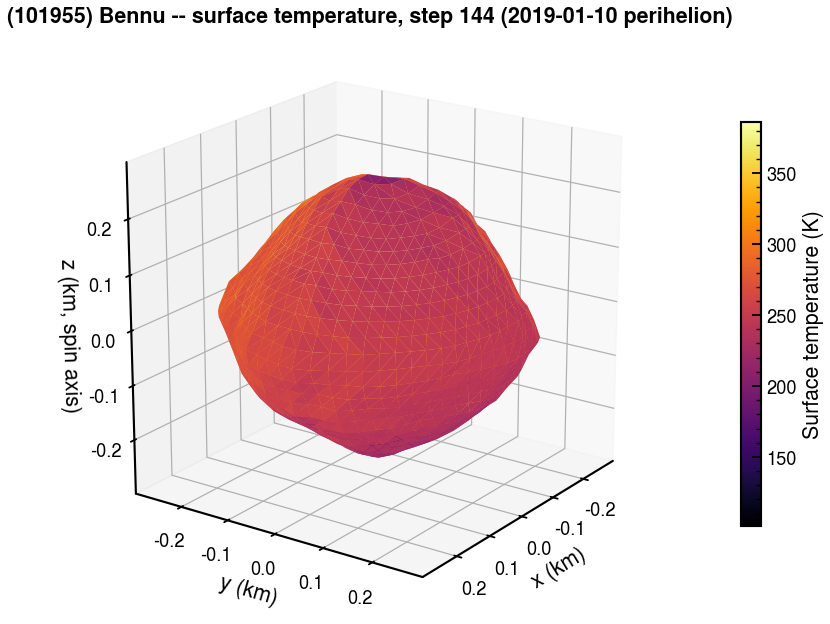

Step 144: T range 101.4-385.8 K, 1315 distinct values of 2692 faces


In [15]:
plt = plots.styled()   # the project's figure style (ptm.pubstyle)
GRID = dict(color="#e1e0d9", linewidth=0.5)
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#898781", "#c0392b"

EPOCH_STEP = 144  # second (settled) rotation, ~afternoon local time
T_epoch = PERIH.field("temperature", EPOCH_STEP)

# A real facet shape, so this one is drawn as the mesh itself rather than as
# an orthographic globe: ptm.plots.globe() normalizes the vertices to a unit
# sphere, which is exactly what should NOT happen to a spinning-top body.
verts, faces = mesh["vertices"], mesh["faces"]
cmap = plt.get_cmap(plots.CMAP_FIELD)
norm = plt.Normalize(vmin=T_epoch.min(), vmax=T_epoch.max())

fig = plt.figure(figsize=(7.5, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.add_collection3d(Poly3DCollection(verts[faces], facecolors=cmap(norm(T_epoch)),
                                     edgecolors="none"))
ax.minorticks_off()   # the style's minor ticks would grid all three 3-D panes
span = np.abs(verts).max()
ax.set_xlim(-span, span); ax.set_ylim(-span, span); ax.set_zlim(-span, span)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=35)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km, spin axis)")
ax.set_title(f"(101955) Bennu -- surface temperature, step {EPOCH_STEP} "
             "(2019-01-10 perihelion)")
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax,
                    shrink=0.6, pad=0.1)
cbar.set_label("Surface temperature (K)")
plt.tight_layout()
plt.show()

print(f"Step {EPOCH_STEP}: T range {T_epoch.min():.1f}-{T_epoch.max():.1f} K, "
      f"{np.unique(np.round(T_epoch,1)).size} distinct values of {T_epoch.size} faces")

Bennu's spinning-top shape (an equatorial ridge, flattened poles) means each
facet's own tilt relative to the Sun and to its neighbors varies with
position, not just latitude — unlike tutorial 03's sphere, where every facet
at a given latitude sees identical geometry. That is the shape's real
contribution to the temperature field: the same diurnal cycle, modulated by
per-facet slope and local horizon shadowing rather than latitude alone.

### 5.2 Equatorial diurnal curve, with the real solar distance

In [16]:
def diurnal_curve(res, lat_max=10.0, n_bins=48):
    """Equatorial local-solar-time curve over the SECOND output rotation.

    Both configs here write two rotations, and the second one is the settled,
    periodic one. Results.local_solar_time_curve() does the binning: per-face
    local noon is the step at which that face's `direct_solar` peaks, and every
    sample is placed on a 24-hour clock relative to it.
    """
    steps = res.steps("temperature")
    return res.local_solar_time_curve(lat_max=lat_max, n_bins=n_bins,
                                      steps=steps[len(steps) // 2:])


lst_p, T_p, lo_p, hi_p, n_eq = diurnal_curve(PERIH)
print(f"{n_eq} equatorial faces binned into {len(lst_p)} local-solar-time bins")
print(f"mean inter-face (25th-75th percentile) band width: "
      f"{(hi_p - lo_p).mean():.1f} K -- shape-driven scatter at fixed local "
      "solar time, absent on tutorial 03's sphere")

478 equatorial faces binned into 48 local-solar-time bins
mean inter-face (25th-75th percentile) band width: 6.0 K -- shape-driven scatter at fixed local solar time, absent on tutorial 03's sphere


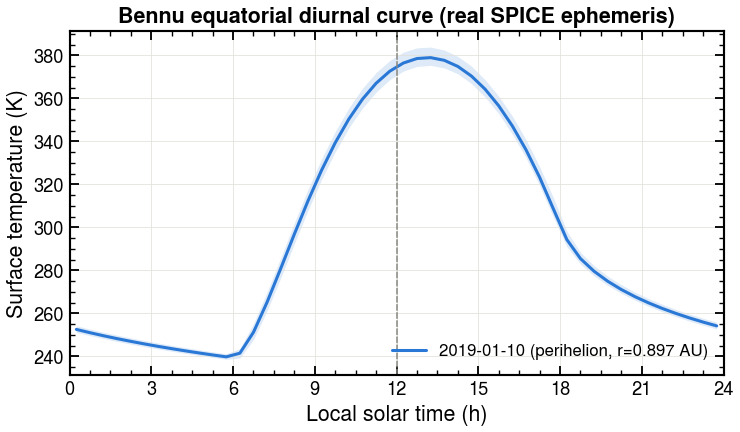

Peak temperature at LST = 13.25 h (75 min after local noon)
Diurnal amplitude (band mean Tmax - Tmin): 139.2 K
r_helio at this epoch: 0.8965 AU, S = 1693.2 W/m^2 (annotated above)


In [17]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lst_p, T_p, color=BLUE, lw=2, label="2019-01-10 (perihelion, r=0.897 AU)")
ax.fill_between(lst_p, lo_p, hi_p, color=BLUE, alpha=0.15, linewidth=0)
ax.axvline(12, color=GREY, lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Bennu equatorial diurnal curve (real SPICE ephemeris)")
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(**GRID)
plt.tight_layout()
plt.show()

peak_lst = lst_p[np.argmax(T_p)]
print(f"Peak temperature at LST = {peak_lst:.2f} h ({(peak_lst-12)*60:.0f} min after local noon)")
print(f"Diurnal amplitude (band mean Tmax - Tmin): {T_p.max()-T_p.min():.1f} K")
print(f"r_helio at this epoch: {r_au:.4f} AU, S = {1361.0/r_au**2:.1f} W/m^2 (annotated above)")

### 5.3 Subsolar temperature vs. rotation phase

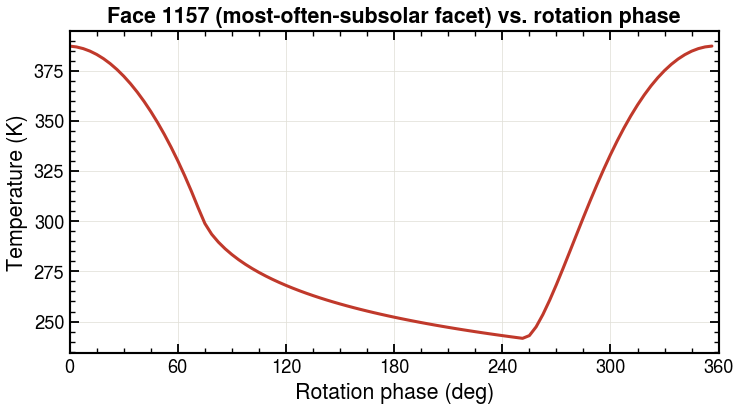

Face 1157: T range 241.6-387.3 K over one 4.297 h rotation


In [18]:
steps = PERIH.steps("temperature")
second_rotation = steps[len(steps) // 2:]
T2 = PERIH.stack("temperature", steps=second_rotation)
F2 = PERIH.stack("direct_solar", steps=second_rotation)

subsolar_face = int(np.argmax(F2.mean(axis=0)))
phase = np.linspace(0, 360, len(second_rotation), endpoint=False)
T_subsolar_face = T2[:, subsolar_face]

fig, ax = plt.subplots(figsize=(7, 4.0))
ax.plot(phase, T_subsolar_face, color=RED, lw=2)
ax.set_xlabel("Rotation phase (deg)")
ax.set_ylabel("Temperature (K)")
ax.set_title(f"Face {subsolar_face} (most-often-subsolar facet) vs. rotation phase")
ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 60))
ax.grid(**GRID)
plt.tight_layout()
plt.show()

print(f"Face {subsolar_face}: T range {T_subsolar_face.min():.1f}-"
      f"{T_subsolar_face.max():.1f} K over one {4.29746:.3f} h rotation")

### 5.4 Perihelion vs. aphelion

Bennu's orbit ($a$=1.129 AU, $e$=0.205) swings its solar flux by more than a
factor of two between perihelion and aphelion — scanning `ephemeris.spk`
across the orbital cycle following the perihelion above finds the matching
aphelion at **2019-08-16, r=1.355 AU**, ~218 days later, well inside the
SPK's coverage. A second short run at that epoch (same config, only
`start_time` and `output.directory` changed) gives the real comparison.

In [19]:
cfg = yaml.safe_load(cfg_path.read_text())
cfg["simulation"]["start_time"] = "2019-08-16T00:00:00"
cfg["output"]["directory"] = "output/quickstart_asteroid_bennu_aphelion"
aph_cfg_path = REPO_ROOT / "examples" / "_bennu_aphelion.yaml"
aph_cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False))

stdout_aph, wall_aph = run_ptm("examples/_bennu_aphelion.yaml", "aphelion 2019-08-16")
APH = Results(REPO_ROOT / "output" / "quickstart_asteroid_bennu_aphelion",
              body_radius_km=BENNU_RADIUS_KM)

S_aph = float(re.search(r"Maximum total flux:\s*([\d.]+)", stdout_aph).group(1))
r_aph = (1361.0 / S_aph) ** 0.5
print(f"\nAphelion peak flux {S_aph:.1f} W/m^2 -> r_helio = {r_aph:.4f} AU"
      f"  (S ratio perihelion/aphelion = {S_measured/S_aph:.2f})")

[aphelion 2019-08-16] rc=0  wall=20.6 s

Aphelion peak flux 742.1 W/m^2 -> r_helio = 1.3542 AU  (S ratio perihelion/aphelion = 2.28)


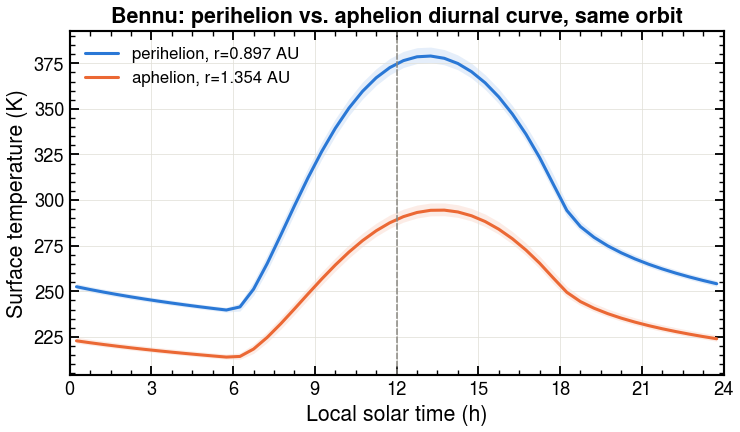

Perihelion: mean equatorial T 296.5 K, amplitude 139.2 K
Aphelion  : mean equatorial T 246.8 K, amplitude 80.6 K


In [20]:
lst_a, T_a, lo_a, hi_a, _ = diurnal_curve(APH)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lst_p, T_p, color=BLUE, lw=2, label=f"perihelion, r={r_au:.3f} AU")
ax.fill_between(lst_p, lo_p, hi_p, color=BLUE, alpha=0.12, linewidth=0)
ax.plot(lst_a, T_a, color=ORANGE, lw=2, label=f"aphelion, r={r_aph:.3f} AU")
ax.fill_between(lst_a, lo_a, hi_a, color=ORANGE, alpha=0.12, linewidth=0)
ax.axvline(12, color=GREY, lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Bennu: perihelion vs. aphelion diurnal curve, same orbit")
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(**GRID)
plt.tight_layout()
plt.show()

print(f"Perihelion: mean equatorial T {T_p.mean():.1f} K, amplitude {T_p.max()-T_p.min():.1f} K")
print(f"Aphelion  : mean equatorial T {T_a.mean():.1f} K, amplitude {T_a.max()-T_a.min():.1f} K")

os.remove(aph_cfg_path)  # generated variant, not a tracked example

## 6. Interpretation: why mission work needs ephemerides

Tutorial 03's Keplerian propagator uses fixed osculating elements from one
reference epoch. Over a handful of orbits that is nearly exact; over years,
unmodeled perturbations (chiefly Earth and Jupiter, for a near-Earth
asteroid) let the real position drift from what those fixed elements alone
would predict. Bennu's config carries the same osculating elements (fit at
J2000.0) as its Keplerian *fallback* block — running this exact config with
`ephemeris_source: keplerian` instead of `spice`, at the *same* calendar
date, isolates that drift directly on this engine, no external orbital
mechanics required.

In [21]:
cfg_kep = yaml.safe_load(cfg_path.read_text())
cfg_kep["generic_body"]["ephemeris_source"] = "keplerian"
cfg_kep["output"]["directory"] = "output/_bennu_keplerian_check"
kep_cfg_path = REPO_ROOT / "examples" / "_bennu_keplerian_check.yaml"
kep_cfg_path.write_text(yaml.safe_dump(cfg_kep, sort_keys=False))

stdout_kep, wall_kep = run_ptm("examples/_bennu_keplerian_check.yaml",
                               "Keplerian fallback, same date")
S_kep = float(re.search(r"Maximum total flux:\s*([\d.]+)", stdout_kep).group(1))
r_kep = (1361.0 / S_kep) ** 0.5

print(f"\n2019-01-10, same shape/spin/thermal properties, position source only differs:")
print(f"  SPICE ephemeris      : S_peak = {S_measured:.1f} W/m^2  (r = {r_au:.4f} AU)")
print(f"  Keplerian fallback   : S_peak = {S_kep:.1f} W/m^2  (r = {r_kep:.4f} AU)")
print(f"  Difference           : {100*(S_measured-S_kep)/S_measured:.1f}% in flux,"
      f" {100*(r_kep-r_au)/r_au:.2f}% in implied distance")
print(f"  -> {(r_kep-r_au)*1.495978707e8:.0f} km difference in heliocentric distance, 19 years"
      f" after the J2000.0 osculating epoch, from perturbations the two-body propagation does not carry.")

os.remove(kep_cfg_path)

[Keplerian fallback, same date] rc=0  wall=9.9 s

2019-01-10, same shape/spin/thermal properties, position source only differs:
  SPICE ephemeris      : S_peak = 1692.8 W/m^2  (r = 0.8965 AU)
  Keplerian fallback   : S_peak = 1648.7 W/m^2  (r = 0.9086 AU)
  Difference           : 2.6% in flux, 1.34% in implied distance
  -> 1799445 km difference in heliocentric distance, 19 years after the J2000.0 osculating epoch, from perturbations the two-body propagation does not carry.


That drift is small in relative terms (a few percent) but it is exactly the
scale that matters for real mission work: a flyby or proximity-operations
targeting solution, a phase-angle-dependent photometric correction, or a
light-time-corrected communication window all need position accuracy well
inside that few-percent band, at a specific calendar date the mission
actually flies — not "some point on the right orbit." `spkpos_c`'s `"LT+S"`
correction (light-time plus stellar aberration) in the SPICE path is the
same kind of real-geometry detail: it is why a navigation team's own
trajectory file, `bennu_refdrmc_v1.bsp` here, is the right source for this
class of problem, and why OSIRIS-REx proximity operations targeted specific
UTC windows rather than "a good day at Bennu."

## 7. Exercises

Each launches one or two more ~30 s CPU runs.

**1. Sample the SPICE-vs-Keplerian drift across the whole orbit.** Section 6
measured the drift at one date (2019-01-10, 19 years past the J2000.0
osculating epoch). Repeat that comparison at a handful of dates spanning
`ephemeris.spk`'s full 2014–2023 coverage and plot the drift vs. time since
the osculating epoch — does it grow roughly linearly, as a first-order
secular perturbation would?

**2. Compare to tutorial 03's Keplerian sphere directly.** Tutorial 03 uses
a synthetic, spatially uniform sphere; run its `RUN_EXERCISES` thermal-inertia
sweep (Exercise 1 there) at TI=300 SI (Bennu's own value here) and compare its
diurnal amplitude/phase to this notebook's Section 5.2 curve. Any remaining
difference is the shape effect Section 5.1 described, isolated from thermal
inertia.

**3. Spin-axis effects.** Bennu's ~178° obliquity means its poles see very
different illumination across an orbit than an equatorial facet does. Extend
`simulation.duration_days` to sample a full orbit (~438 days -- well beyond
"laptop-tutorial" territory, so treat this as a pointer, not a cell to run
here) and compare a polar facet's seasonal temperature swing to the
equatorial band's.

## Provenance

Executed end to end (`jupyter nbconvert --execute`) against the binary and
commit printed in Section 1, in the `europa_viz` conda environment. Bennu's
shape, spin, and ephemeris data are cited at their point of use above;
re-running this notebook from a clean clone reproduces the same physics
(deterministic given the config) with exact K values that may drift slightly
with engine changes between commits, same as tutorials 01–03.